[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.3/Problem_3.9.ipynb)

# Chapter 3, Problem 9 — reading a gradient off a contour map

**Problem (paraphrased).** Fig. 3.5 shows curves of equal temperature $T$ (isotherms) on a metal plate. At the points P and Q shown, estimate the components of the gradient $\tilde dT$. (Hint: the components are the contractions with the basis vectors, which can be estimated by counting the number of isotherms crossed by the vectors.)

> **About the figure.** The text of the book I have doesn't include Fig. 3.5's drawing, only its labels (isotherms marked 0, 10, 20, 30; $x$ from 0 to 3 and $y$ from 0 to 2). So the specific values at P and Q can't be read here. This notebook gives the complete **method**, works it on a stand-in temperature map where the exact answer is known, and ends with a cell where you enter your readings from the real Fig. 3.5. If you send a picture of the figure, I'll fill in P and Q.

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## The method

By Eq. (3.15) the components of the gradient in $(x, y)$ coordinates are
$$
(\tilde dT)_x = \tilde dT(\vec e_x) = \frac{\partial T}{\partial x},\qquad (\tilde dT)_y = \tilde dT(\vec e_y) = \frac{\partial T}{\partial y}.
$$
The value of $\tilde dT$ on a vector is the change of $T$ along it, i.e. the number of isotherm "steps" it crosses times the step size. So:

1. **Draw $\vec e_x$ at the point** (a short arrow one unit long in $+x$; or a shorter arrow of length $\delta$ if the isotherms curve noticeably over one unit).
2. **Count isotherm crossings along it**, with sign: $+$ if $T$ increases along the arrow, $-$ if it decreases. Interpolate fractions between isotherms.
3. **Multiply by the isotherm spacing** $\Delta T$ (here 10 degrees) and divide by the arrow length $\delta$:
$$
(\tilde dT)_x \approx \frac{(\text{signed number of isotherms crossed})\times\Delta T}{\delta}.
$$
4. **Repeat with $\vec e_y$** for $(\tilde dT)_y$.

The geometric picture: the gradient one-form's "surfaces" near the point are the isotherms. Where they're **close together**, $\tilde dT$ is **large**. A vector **along** an isotherm crosses none, so $\tilde dT$ vanishes on vectors tangent to the isotherms (Problem 13).

**Common pitfall.** The components come from counting along the **coordinate directions**, not along the steepest direction. If the isotherms run diagonally, both components are nonzero.

## Worked example on a stand-in plate

Take $T(x, y) = 10\,(x^2 + 2xy - y^2 + 2)$ on $0 \le x \le 3$, $0 \le y \le 2$, with isotherms every $10^\circ$. Two sample points, P $= (1, 1)$ and Q $= (2.5, 0.5)$. Below: (1) the contour map with the unit basis vectors drawn at P and Q; (2) the crossing-count estimate, done by sampling $T$ along each arrow; (3) the exact partial derivatives for comparison.

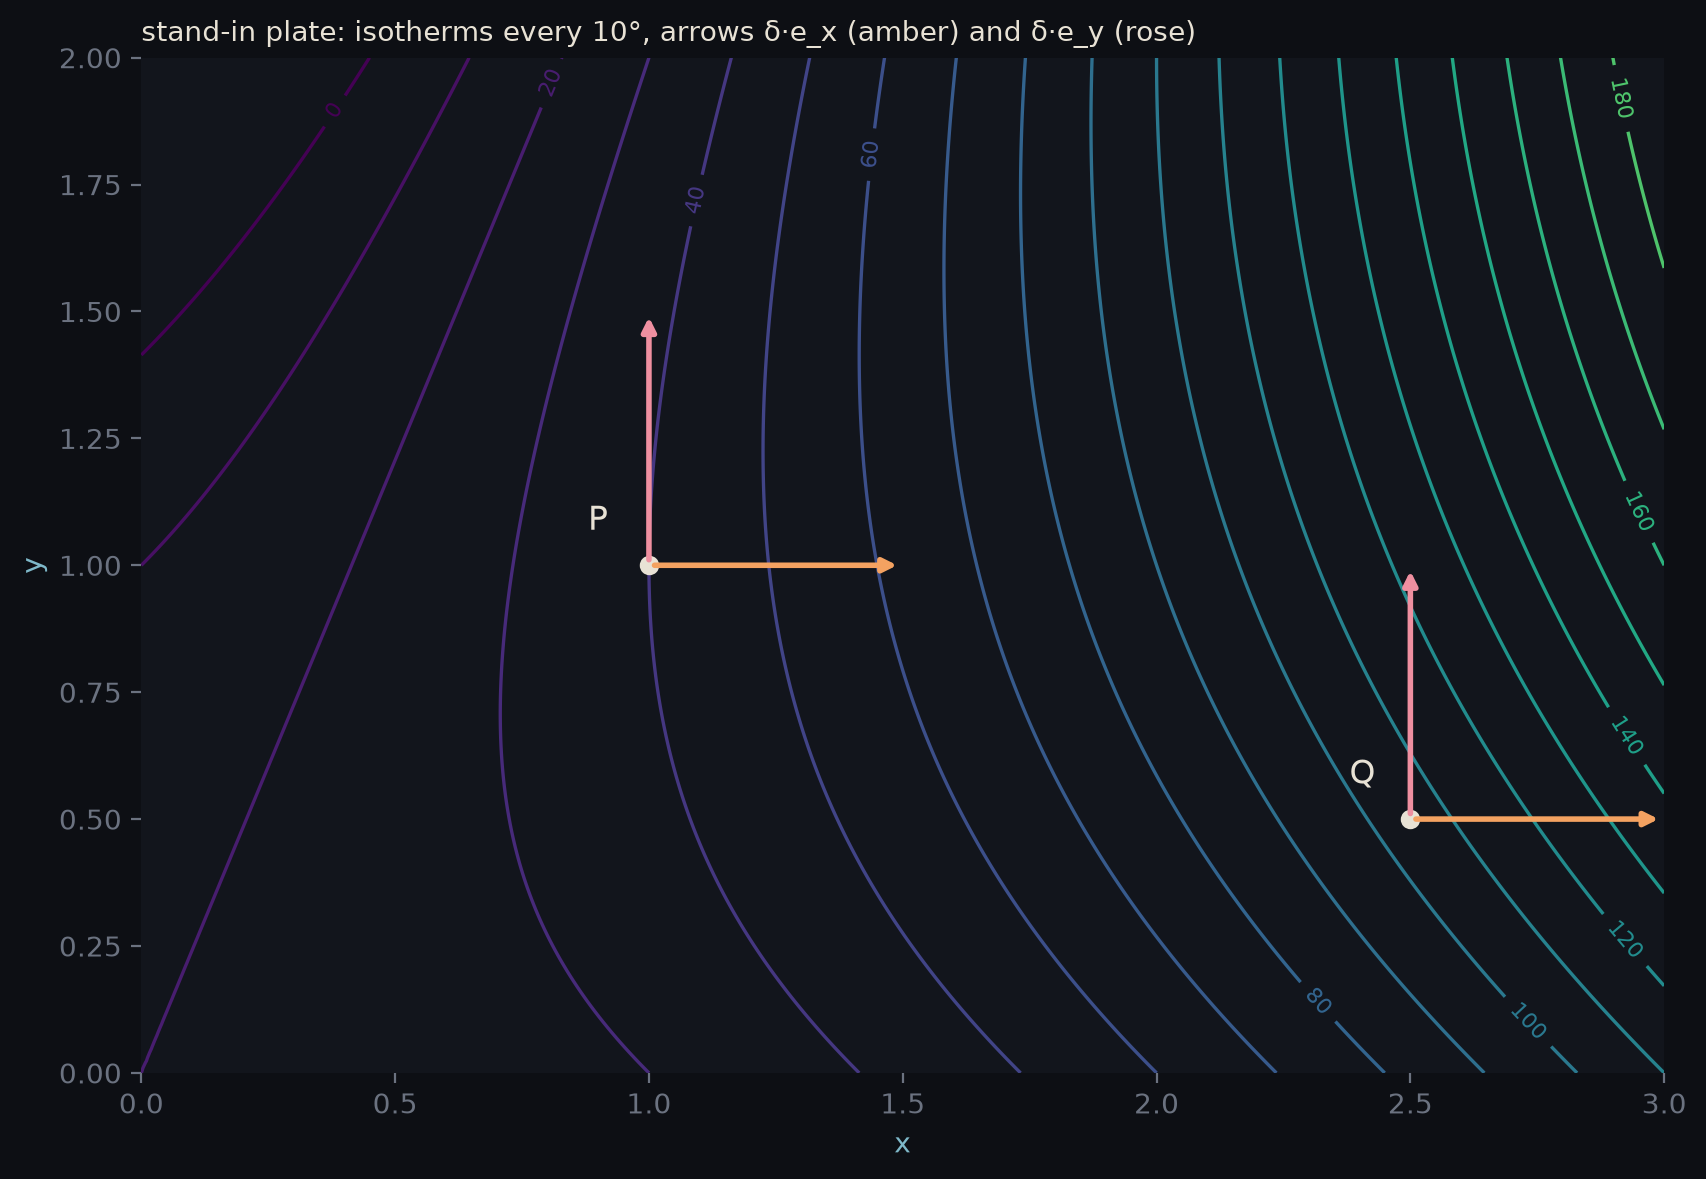

P: exact d̃T = (+40.0, +0.0) degrees per unit
   δ = 1.0: crossings along δe_x = +5.00, along δe_y = -1.00  →  d̃T ≈ (+50.0, -10.0)
   δ = 0.5: crossings along δe_x = +2.25, along δe_y = -0.25  →  d̃T ≈ (+45.0, -5.0)
   δ = 0.1: crossings along δe_x = +0.41, along δe_y = -0.01  →  d̃T ≈ (+41.0, -1.0)
Q: exact d̃T = (+60.0, +40.0) degrees per unit
   δ = 1.0: crossings along δe_x = +7.00, along δe_y = +3.00  →  d̃T ≈ (+70.0, +30.0)
   δ = 0.5: crossings along δe_x = +3.25, along δe_y = +1.75  →  d̃T ≈ (+65.0, +35.0)
   δ = 0.1: crossings along δe_x = +0.61, along δe_y = +0.39  →  d̃T ≈ (+61.0, +39.0)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'

T = lambda x, y: 10*(x**2 + 2*x*y - y**2 + 2)
dTdx = lambda x, y: 10*(2*x + 2*y); dTdy = lambda x, y: 10*(2*x - 2*y)
step = 10.0
pts = {"P": (1.0, 1.0), "Q": (2.5, 0.5)}
delta = 0.5                                   # short arrows: the isotherms curve over one full unit

X, Y = np.meshgrid(np.linspace(0, 3, 300), np.linspace(0, 2, 200))
fig, ax = plt.subplots(figsize=(9, 6)); fig.patch.set_facecolor(COLORS["bg"]); ax.set_facecolor(COLORS["panel"])
levels = np.arange(0, 260, step)
cs = ax.contour(X, Y, T(X, Y), levels=levels, cmap="viridis", linewidths=1.2)
ax.clabel(cs, levels[::2], fontsize=8, fmt="%d")
for name, (x0, y0) in pts.items():
    ax.plot(x0, y0, "o", color=COLORS["text"]); ax.text(x0 - 0.12, y0 + 0.07, name, color=COLORS["text"], fontsize=12)
    ax.annotate("", xy=(x0 + delta, y0), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=COLORS["amber"], lw=2))
    ax.annotate("", xy=(x0, y0 + delta), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=COLORS["rose"], lw=2))
ax.set_aspect("equal"); ax.tick_params(colors=COLORS["grey"])
ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("y", color=COLORS["teal"])
ax.set_title("stand-in plate: isotherms every 10°, arrows δ·e_x (amber) and δ·e_y (rose)", color=COLORS["text"], loc="left", fontsize=10)
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

for name, (x0, y0) in pts.items():
    print(f"{name}: exact d̃T = ({dTdx(x0, y0):+.1f}, {dTdy(x0, y0):+.1f}) degrees per unit")
    for d in (1.0, 0.5, 0.1):
        # "count isotherms crossed" = change in T along the arrow, in units of the isotherm step
        nx = (T(x0 + d, y0) - T(x0, y0)) / step
        ny = (T(x0, y0 + d) - T(x0, y0)) / step
        print(f"   δ = {d:3.1f}: crossings along δe_x = {nx:+.2f}, along δe_y = {ny:+.2f}  →  d̃T ≈ ({nx*step/d:+.1f}, {ny*step/d:+.1f})")

With full unit arrows the count is off by several degrees per unit, because the isotherms bend over that distance; the estimate converges to the exact gradient as $\delta$ shrinks (the isotherms look straighter on smaller scales). That's the "one-forms are local" point of §3.3: the true $\tilde dT$ at a point is the limit of this counting as the arrow shrinks.

## Your readings from Fig. 3.5

Count, at each of P and Q, how many isotherms a short arrow along $+x$ and along $+y$ crosses (signed, with fractions), and set the arrow length you used. The cell turns the counts into gradient components.

In [3]:
# ▶ Fill in from Fig. 3.5 (isotherms are 10 degrees apart). Signed number of isotherms crossed by an arrow of length delta:
readings = {
    "P": {"delta": 1.0, "crossings_x": None, "crossings_y": None},
    "Q": {"delta": 1.0, "crossings_x": None, "crossings_y": None},
}
step = 10.0
for name, r in readings.items():
    if None in (r["crossings_x"], r["crossings_y"]):
        print(f"{name}: enter your counts above")
    else:
        print(f"{name}: d̃T ≈ ({r['crossings_x']*step/r['delta']:+.1f}, {r['crossings_y']*step/r['delta']:+.1f}) degrees per unit length")

P: enter your counts above
Q: enter your counts above
